# EN.605.631 — Additional Topics in Probability with R (Chapter 9)

**Format:** Jupyter Notebook (**R kernel**)  
**Estimated time:** ~5 hours  
**Total points:** 100

This notebook includes **problem prompts**, **stubs**, and **plotting scaffolds** for each task. Replace all `TODO` comments with your solutions.

In [1]:
# Environment & Setup
R.version.string
sessionInfo()
set.seed(631)

# Optional packages (base R preferred)
# suppressPackageStartupMessages({
#   library(ggplot2)
#   library(dplyr)
#   library(markovchain)
# })

[1] "R version 4.6.1 (2026-06-24 ucrt)"

R version 4.6.1 (2026-06-24 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default
  LAPACK version 3.12.1

locale:
[1] LC_COLLATE=English_United States.utf8 
[2] LC_CTYPE=English_United States.utf8   
[3] LC_MONETARY=English_United States.utf8
[4] LC_NUMERIC=C                          
[5] LC_TIME=English_United States.utf8    

time zone: America/New_York
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
 [1] digest_0.6.39     IRdisplay_1.1     base64enc_0.1-6   fastmap_1.2.0    
 [5] glue_1.8.1        htmltools_0.5.9   repr_1.1.7        lifecycle_1.0.5  
 [9] cli_3.6.6         vctrs_0.7.3       textshaping_1.0.5 pbdZMQ_0.3-14    
[13] systemfonts_1.3.2 compiler_4.6.1    tools_4.6.1       ragg_1.5.2       
[17] evaluate_1.0.5    pillar_1.11.1     rlang_1.3.0       jsonlite_2.0.0   
[21] crayon_1.5.3      IRkernel_1.

In [2]:
# Helper utilities (you may add more)
mc_se_mean <- function(x) sd(x)/sqrt(length(x))
ci95_prop <- function(p_hat, n){
  se <- sqrt(p_hat*(1-p_hat)/n)
  c(lower = max(0, p_hat - 1.96*se),
    upper = min(1, p_hat + 1.96*se))
}

## Problem 1 — Poisson Process Basics (10 pts)

In [3]:
# ============================================================
# ✅ TODO LIST — Problem 1: Poisson process basics
# ============================================================
# Analytic tasks:
# 1. Write out the Poisson process axioms (small-h assumptions).
# 2. Derive P{N(t)=0} = exp(-λt) using the differential equation for p0(t).
# 3. Show that P(T1 > t) = P(N(t)=0) ⇒ T1 ~ Exp(λ).
# 4. Explain why interarrival times are i.i.d. exponentials.
#
# Simulation tasks (R code):
# 5. Set rate λ = 2 events/minute and N = 1e5 simulations.
# 6. Simulate N(t) for t = 1 minute using rpois; estimate P(N(1)=0).
# 7. Simulate interarrival times rexp(N, rate = λ);
#    - Compute empirical mean & sd and compare to theoretical 1/λ.
# 8. Plot histogram of T1 with theoretical Exp(λ) pdf overlaid.
# 9. Generate multiple interarrival sequences and compute lag-1
#    autocorrelation to test independence.
# 10. Summarize key quantities: P(N(1)=0), mean/sd of T1,
#     and estimated autocorrelation.
# 11. Write a short interpretation:
#     - Do empirical and theoretical results match within MC error?
#     - Is autocorrelation near 0 (independence of interarrivals)?
# ============================================================


### 1. Poisson process axioms

function $f$ is $o(h)$ if $\lim_{h\to 0}\frac{f(h)}{h}=0$

Let $N(t)$ denote the number of events in $[0,t]$

$\{N(t),\,t\ge 0\}$ is a Poisson process having rate $\lambda>0$ if:

(i) $N(0)=0$

(ii) the numbers of events in disjoint time intervals are independent

(iii) the distribution of the number of events in an interval depends only on the length and not its location

(iv) $P\{N(h)=1\}=\lambda h+o(h)$

(v) $P\{N(h)\ge 2\}=o(h)$

### 2. $P\{N(t)=0\} = e^{(-\lambda t)}$

Let $P_0(t)=P\{N(t)=0\}$. We derive a differential equation for $P_0(t)$

$P_0(t+h) = P\{N(t+h)=0\}$

$= P\{N(t)=0, N(t+h)-N(t)=0\} $

$= P\{N(t)=0\}\,P\{N(t+h)-N(t)=0\} $

$= P_0(t)\,[1-\lambda h+o(h)]$

where the final two equations follow from condition (ii) plus the fact that conditions (iv) and (v) imply that $P\{N(h)=0\}=1-\lambda h+o(h)$

Hence, $\dfrac{P_0(t+h)-P_0(t)}{h}=-\lambda P_0(t)+\dfrac{o(h)}{h}$

Now letting $h\to 0$, we obtain $P_0'(t)=-\lambda P_0(t)$

or equivalently, $\dfrac{P_0'(t)}{P_0(t)}=-\lambda$

which implies by integration that $\log P_0(t)=-\lambda t+c$

or $P_0(t)=Ke^{-\lambda t}$

Since $P_0(0)=P\{N(0)=0\}=1$, we arrive at $P_0(t)=e^{-\lambda t}$

### 3.  $P(T_1 > t) = P(N(t)=0) ⇒ T_1 ~ e^{λ}$

$\{T_1 > t\}$ takes place iff no events of the Poisson process occur in the interval $[0, t]$

$P\{T_1>t\}=P\{N(t)=0\}=e^{-\lambda t}$

CDF of Exp($\lambda$): $F_{T_1}(t)=1-P\{T_1>t\}=1-e^{-\lambda t}, t\ge 0$

$f_{T_1}(t)=\dfrac{d}{dt}F_{T_1}(t)=\lambda e^{-\lambda t}, t\ge 0$

Hence $T_1$ has an exponential distribution with mean $1/\lambda$

### 4. Interarrival times are iid exponentials

For a Poisson process let $T_1$ denote the time the first event occurs. For $n>1$ let $T_n$ denote the time elapsed between the $(n-1)$st and the $n$th event. The sequence $\{T_n,\; n=1,2,\dots\}$ is called the sequence of interarrival times. If $T_1=5$ and $T_2=10$ then the first event of the Poisson process would have occurred at time 5 and the second at time 15.

Now determine the distribution of the $T_n$. The event $\{T_1>t\}$ takes place if and only if no events of the Poisson process occur in the interval $[0,t]$

Thus $P\{T_1>t\}=P\{N(t)=0\}=e^{-\lambda t}$

Hence, $T_1$ has an exponential distribution with mean $1/\lambda$

$P\{T_2>t\}=E\big[P\{T_2>t\mid T_1\}\big]$

$P\{T_2>t\mid T_1=s\} = P\{0 \text{ events in } (s,s+t]\mid T_1=s\} $

$= P\{0 \text{ events in } (s,s+t]\}$

$= e^{-\lambda t}$ where the last two equations followed from the assumptions about independent and stationary increments. 

We conclude that $T_2$ is also an exponential random variable with mean $1/\lambda$ and, furthermore, that $T_2$ is independent of $T_1$. Repeating the same argument yields that interarrival times are i.i.d exponential random variables

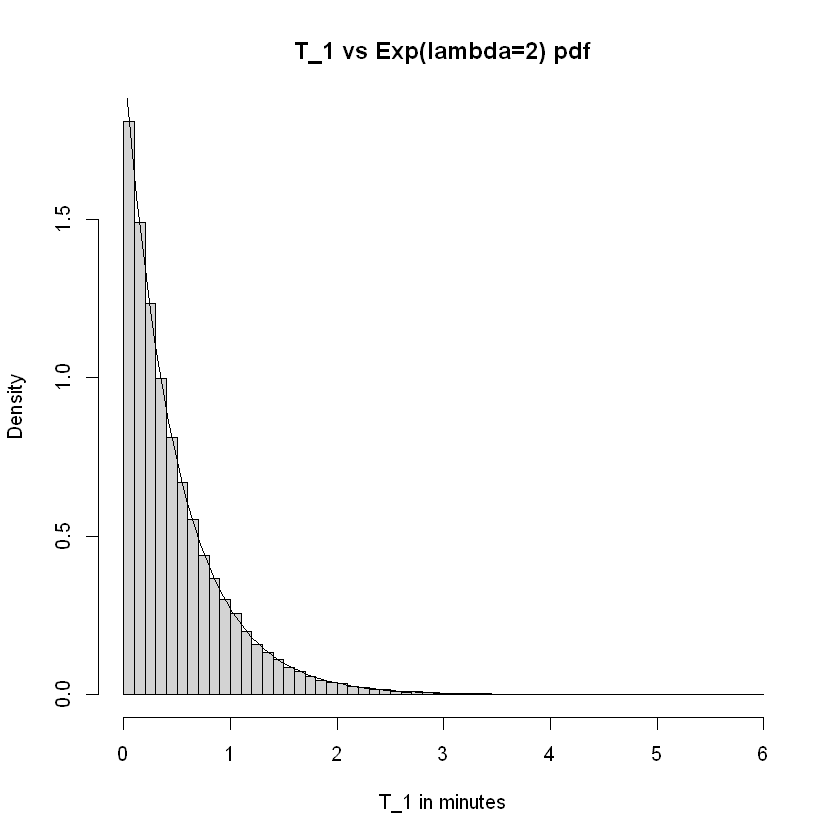

In [4]:
set.seed(631)

# Simulation tasks (R code):
# 5. Set rate λ = 2 events/minute and N = 1e5 simulations.
lambda <- 2
N <- 1e5

# 6. Simulate N(t) for t = 1 minute using rpois; estimate P(N(1)=0).
Nt <- rpois(N, lambda * 1)
p_hat <- mean(Nt == 0)

# 7. Simulate interarrival times rexp(N, rate = λ);
#    - Compute empirical mean & sd and compare to theoretical 1/λ.
T1 <- rexp(N, lambda)
T1_mean <- mean(T1)
T1_sd <- sd(T1)
T1_se <- mc_se_mean(T1)
T1_prop <- ci95_prop(p_hat, N)
p_theoretical <- exp(-lambda * 1)

# 8. Plot histogram of T1 with theoretical Exp(λ) pdf overlaid.
hist(T1, breaks=60, freq=FALSE, main="T_1 vs Exp(lambda=2) pdf", xlab="T_1 in minutes")

curve(dexp(x, rate = lambda), from=0, to=6, add=TRUE)

In [5]:
# 9. Generate multiple interarrival sequences and compute lag-1
#    autocorrelation to test independence.


# 10. Summarize key quantities: P(N(1)=0), mean/sd of T1,
#     and estimated autocorrelation.
p_hat
p_theoretical
T1_mean
mean_theoretical <- 1/lambda
mean_theoretical
T1_sd
sd_theoretical <- 1/lambda
sd_theoretical
T1_prop
T1_se

[1] 0.13548

[1] 0.1353353

[1] 0.4957166

[1] 0.5

[1] 0.4935269

[1] 0.5

lower     upper 
0.1333588 0.1376012

[1] 0.001560669

## Problem 2 — Arrival Times as Gamma; Poisson Counts (10 pts)

In [6]:
# # ============================================================
# ✅ TODO LIST — Problem 2: Arrival times as Gamma; Poisson counts
# ============================================================
# Analytic tasks:
# 1. Recall that the n-th arrival time S_n = T1 + ... + Tn
#    is the sum of n i.i.d. Exp(λ) interarrivals.
# 2. Derive the pdf of S_n and show that S_n ~ Gamma(shape = n, rate = λ).
# 3. Explain intuitively why Gamma arises as the waiting time for n events.
# 4. Recall that for any t > 0, the count N(t) ~ Poisson(λt).
#


### Derive the pdf of $S_n$ and show that $S_n \~ Gamma(n, λ)$

$T_1,T_2,\dots,T_n$ are independent exponential random variables, each with mean $1/\lambda$.

$S_n$ is the arrival time of the $n$th event, also called waiting time until the $n$th event

$S_n=\sum_{i=1}^{n}T_i, n\ge 1$

A random variable is said to have a gamma distribution with parameters $(\alpha,\lambda)$, $\lambda>0$, $\alpha>0$ if its density function is given by

$f(x)=\{\dfrac{\lambda e^{-\lambda x}(\lambda x)^{\alpha-1}}{\Gamma(\alpha)} \text{ if } x\ge 0 \text{ and } 0 \text{ if } x<0\}$

where $\Gamma(\alpha)$ is defined as $\Gamma(\alpha)=\int_0^{\infty}e^{-y}y^{\alpha-1}\,dy$

Integration of $\Gamma(\alpha)$ by parts yields

$\Gamma(\alpha)=-e^{-y}y^{\alpha-1}\Big|_0^{\infty}+\int_0^{\infty}e^{-y}(\alpha-1)y^{\alpha-2}\,dy$

$=(\alpha-1)\int_0^{\infty}e^{-y}y^{\alpha-2}\,dy$

$=(\alpha-1)\Gamma(\alpha-1)$

For integral values of $\alpha$, say, $\alpha=n$, we obtain

$\Gamma(n)=(n-1)\Gamma(n-1)=(n-1)(n-2)\Gamma(n-2)=\cdots =(n-1)(n-2)\cdots 3\cdot 2\,\Gamma(1)$

Since $\Gamma(1)=\int_0^{\infty}e^{-x}\,dx=1$, it follows that, for integral values of $n$, $\Gamma(n)=(n-1)!$

When $\alpha$ is a positive integer, say, $\alpha=n$, the gamma distribution with parameters $(\alpha,\lambda)$ often arises, in practice, as the distribution of the amount of time one has to wait until a total of $n$ events has occurred. More specifically, if events are occurring randomly and in accordance with the three axioms of Section 4.7, then it turns out that the amount of time one has to wait until a total of $n$ events has occurred will be a gamma random variable with parameters $(n,\lambda)$. To prove this, let $S_n$ denote the time at which the $n$th event occurs, and note that $S_n$ is less than or equal to $t$ if and only if the number of events that have occurred by time $t$ is at least $n$. That is, with $N(t)$ equal to the number of events in $[0,t]$,

$P\{S_n\le t\}=P\{N(t)\ge n\}=\sum_{j=n}^{\infty}P\{N(t)=j\}=\sum_{j=n}^{\infty}\frac{e^{-\lambda t}(\lambda t)^j}{j!}$

where the final identity follows because the number of events in $[0,t]$ has a Poisson distribution with parameter $\lambda t$. Differentiation of the preceding now yields the density function of $S_n$

$f(t)=\sum_{j=n}^{\infty}\frac{e^{-\lambda t}j(\lambda t)^{j-1}\lambda}{j!}-\sum_{j=n}^{\infty}\frac{\lambda e^{-\lambda t}(\lambda t)^j}{j!}$

$=\sum_{j=n}^{\infty}\frac{\lambda e^{-\lambda t}(\lambda t)^{j-1}}{(j-1)!}-\sum_{j=n}^{\infty}\frac{\lambda e^{-\lambda t}(\lambda t)^j}{j!}$

$=\frac{\lambda e^{-\lambda t}(\lambda t)^{n-1}}{(n-1)!}$

Therefore, $S_n$ has a gamma distribution with parameters $n$ and $\lambda$ ands the PDF is given by

$f_{S_n}(x)=\lambda e^{-\lambda x}\dfrac{(\lambda x)^{n-1}}{(n-1)!}, x\ge 0$

### Gamma for arrival times

$S_n$ is the total of $n$ independent waiting times each Exp$(\lambda)$

$E[S_n]=n/\lambda$ and $\mathrm{Var}(S_n)=n/\lambda^2$

The cancellation reflects that $S_n\le t$ when at least $n$ events land in $[0,t]$

For $n=1$ the Gamma reduces to the exponential

### Poisson counts

For any $t>0$, $P\{N(t)=k\}=\dfrac{e^{-\lambda t}(\lambda t)^k}{k!},\quad k=0,1,2,\dots$

For $\lambda=3$ and $t=2$

$N(2)\sim\text{Poisson}(6)$

$P\{N(2)=k\}=\dfrac{e^{-6}6^k}{k!}$

In [7]:
set.seed(631)

# Simulation tasks (R code):
# 5. Set λ = 3 (per hour) and number of replications N = 2e5.
lambda <- 3
N <- 2e5

# 6. Simulate S5 = sum of 5 exponential(λ) interarrivals using rgamma
#    or by summing rexp draws. Check that mean ≈ n/λ and var ≈ n/λ².
n <- 5
S5 <- rowSums(matrix(rexp(N * n, lambda), N))
mean(S5)
n/lambda
var(S5)
n/(lambda^2)

[1] 1.664644

[1] 1.666667

[1] 0.5525524

[1] 0.5555556

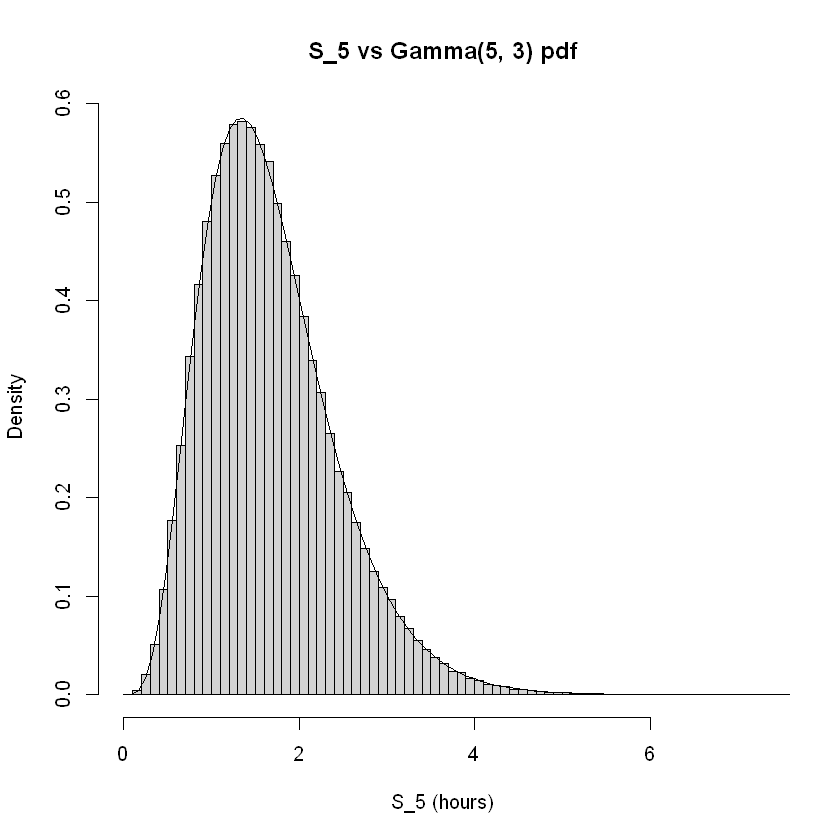

In [8]:
# 7. Plot histogram or density of S5 with Gamma(5, 3) pdf overlaid.
hist(S5, breaks=60, freq=FALSE, main="S_5 vs Gamma(5, 3) pdf", xlab="S_5 (hours)")
curve(dgamma(x, n, lambda), from=0, to=8, add=TRUE)

[1] 0.002420 0.014630 0.044840 0.089360 0.133700 0.160775 0.160265 0.137715
 [9] 0.103605 0.068880 0.041365 0.022070 0.011185

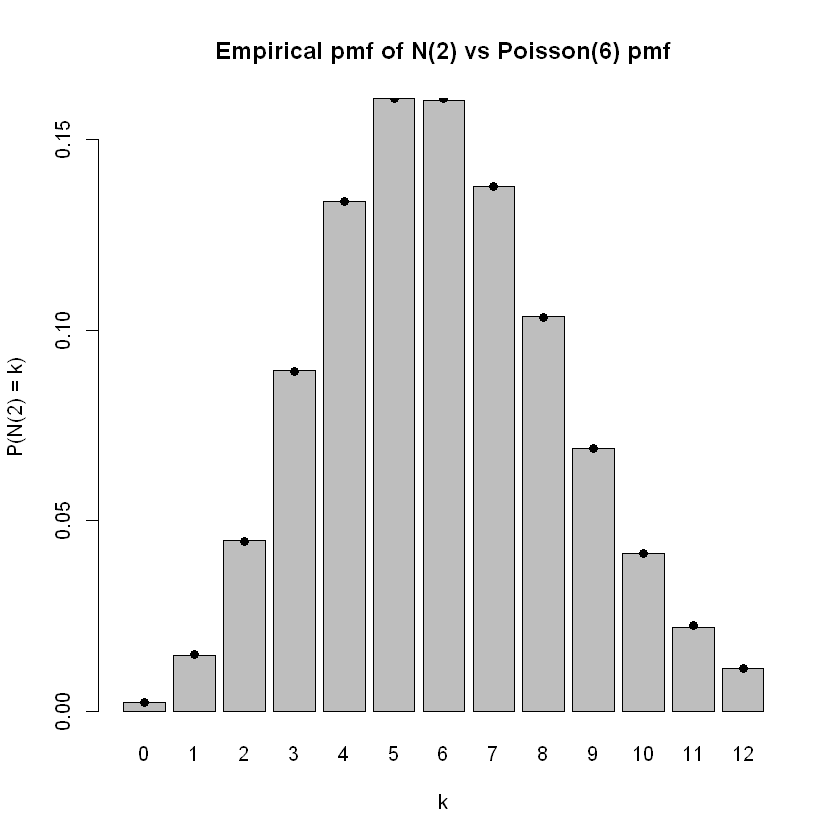

In [9]:
# 8. Simulate counts N(2) using rpois(N, λ * 2) for t = 2 hours.
t <- 2
Nt <- rpois(N, lambda * t)

# 9. Compute empirical pmf of N(2) for k = 0, 1, …, 12.
k <- 0:12
p_emp <- sapply(k, function(j) mean(Nt == j))
p_emp

# 10. Overlay empirical pmf with theoretical Poisson(λt) pmf.
p_theoretical <- dpois(k, lambda * t)
bp <- barplot(p_emp, names.arg=k, xlab="k", ylab="P(N(2) = k)", main="Empirical pmf of N(2) vs Poisson(6) pmf")
points(bp, p_theoretical, pch = 19)
                
# 11. Interpret:
#     - Does the Gamma model fit the arrival time distribution?
#     - Do simulated Poisson counts align with theoretical values?
# ============================================================

Yes! The Gamma model is a very close fit for the arrival times, and the empirical PMF matches the poisson counts for every k.

## Problem 3 — Highway-Crossing Risk (10 pts)

In [10]:
# ============================================================
# ✅ TODO LIST — Problem 3: Highway-crossing risk (Poisson process)
# ============================================================
# Setup & Analytic tasks:
# 1. Convert the rate to per-second units:
#    - Given λ = 3 cars/minute, set λ_s = 3/60 cars/second.
# 2. For each window length s ∈ {2, 5, 10, 20} seconds, derive:
#    - P{no cars in (0, s)} = exp(−λ_s * s).
#    - P{≤ 1 car in (0, s)} = exp(−λ_s * s) * (1 + λ_s * s).
# 3. Create a tidy table with columns: s, p0_theory, ple1_theory.
#

$\lambda = 3$ cars/minute

$\lambda_s=\dfrac{3}{60}=0.05$ cars/second

In an interval of length $s$ seconds the mean for a Poisson process is $\lambda_s s=0.05\,s$ cars passing

For a Poisson process with rate $\lambda$, $P\{N(t)=0\}=e^{-\lambda t}$ and $P\{N(t)=n\}=\dfrac{e^{-\lambda t}(\lambda t)^n}{n!}$ (see Problem 1)

Let time be seconds so$\lambda=\lambda_s$ and $t=s$

$P\{$no cars in $(0,s)\}=P\{N(s)=0\}=e^{-\lambda_s s}$

$P\{\le 1$ car in $(0,s)\}=P\{N(s)\le 1\}=P\{N(s)=0\}+P\{N(s)=1\}=e^{-\lambda_s s}+\dfrac{e^{-\lambda_s s}(\lambda_s s)^1}{1!}=e^{-\lambda_s s}\,(1+\lambda_s s)$

$\begin{array}{c|c|c|c}
s \text{ (sec)} & \lambda_s s & p_0 & p_{\le 1}\\ \hline
2  & 0.10 & 0.904837 & 0.995321\\
5  & 0.25 & 0.778801 & 0.973501\\
10 & 0.50 & 0.606531 & 0.909796\\
20 & 1.00 & 0.367879 & 0.735759
\end{array}$

In [11]:
set.seed(631)

# Simulation tasks (R code):
# 4. Set number of Monte Carlo trials R = 5e5 (or as allowed by runtime).
lambda_s <- 0.05
s_vec <- c(2, 5, 10, 20)
R <- 5e5

# 5. For each s, simulate counts via X ~ Poisson(λ_s * s) using rpois(R, λ_s * s).
X <- lapply(s_vec, function(s) rpois(R, lambda_s * s))
names(X) <- s_vec

# 6. Estimate:
#    - p0_emp = mean(X == 0)
#    - ple1_emp = mean(X <= 1)
p0_emp <- unname(sapply(X, function(x) mean(x == 0)))
ple1_emp <- unname(sapply(X, function(x) mean(x <= 1)))


# 7. Compute Monte Carlo standard errors (SE) and 95% CIs:
#    - SE(p̂) = sqrt(p̂*(1−p̂)/R)
#    - CI95 = p̂ ± 1.96 * SE
se_p_hat <- data.frame(s=s_vec, p0=sqrt(p0_emp * (1 - p0_emp) / R), ple1=sqrt(ple1_emp * (1 - ple1_emp) / R))
ci_95 <- list(p0 = data.frame(s=s_vec, lower=p0_emp - 1.96 * se_p_hat$p0, upper=p0_emp + 1.96 * se_p_hat$p0),
              ple1 = data.frame(s=s_vec, lower=ple1_emp - 1.96 * se_p_hat$ple1, upper=ple1_emp + 1.96 * se_p_hat$ple1))

# 8. Compute absolute and relative errors vs theory:
#    - |p̂ − p_theory| and |p̂ − p_theory| / p_theory.
p0_theory   <- exp(-lambda_s * s_vec)
ple1_theory <- exp(-lambda_s * s_vec) * (1 + lambda_s * s_vec)

abs_err_p0    <- abs(p0_emp - p0_theory)
rel_err_p0    <- abs_err_p0 / p0_theory
abs_err_ple1  <- abs(ple1_emp - ple1_theory)
rel_err_ple1  <- abs_err_ple1 / ple1_theory

# 9. Assemble a final results table with: s, theory, estimate, SE, CI_low, CI_high,
#    abs_err, rel_err for both “no cars” and “≤ 1 car”.
results_no_cars <- data.frame(s = s_vec, event = "no cars",
    theory = p0_theory, estimate = p0_emp, SE = se_p_hat$p0,
    CI_low = ci_95$p0$lower, CI_high = ci_95$p0$upper,
    abs_err = abs_err_p0, rel_err = rel_err_p0)
print(results_no_cars, digits = 5)

results_le1 <- data.frame(s = s_vec, event = "<=1 car",
    theory = ple1_theory, estimate = ple1_emp, SE = se_p_hat$ple1,
    CI_low = ci_95$ple1$lower, CI_high = ci_95$ple1$upper,
    abs_err = abs_err_ple1, rel_err = rel_err_ple1)
print(results_le1, digits = 5)
            
#
# Optional visualization (nice but not required):
# 10. Plot, for each s, the empirical pmf (barplot of counts) with Poisson(λ_s*s)
#     overlay for k = 0, 1, 2, … to illustrate small-window behavior.
#
# Interpretation:
# 11. Briefly discuss:
#     - Do empirical probabilities fall within the 95% CIs around theory?
#     - How does “safety” (P{no cars}, P{≤1}) decay as s increases?
#     - Any noticeable Monte Carlo variability and its dependence on R?
# ============================================================

   s   event  theory estimate         SE  CI_low CI_high    abs_err    rel_err
1  2 no cars 0.90484  0.90439 0.00041585 0.90358 0.90521 0.00044542 0.00049226
2  5 no cars 0.77880  0.77985 0.00058597 0.77870 0.78100 0.00105122 0.00134979
3 10 no cars 0.60653  0.60638 0.00069092 0.60502 0.60773 0.00015466 0.00025499
4 20 no cars 0.36788  0.36748 0.00068182 0.36615 0.36882 0.00039544 0.00107492
   s   event  theory estimate         SE  CI_low CI_high    abs_err    rel_err
1  2 <=1 car 0.99532  0.99536 9.6109e-05 0.99517 0.99555 0.00003884 3.9023e-05
2  5 <=1 car 0.97350  0.97326 2.2814e-04 0.97281 0.97371 0.00024098 2.4754e-04
3 10 <=1 car 0.90980  0.91010 4.0452e-04 0.90931 0.91089 0.00030401 3.3415e-04
4 20 <=1 car 0.73576  0.73556 6.2372e-04 0.73434 0.73678 0.00019688 2.6759e-04


Almost all values fall within the 95% CI. The safety decreases the rate of cars increases. The SE decreases as R increases and RE is largest where s is larger and probabilities are smaller.

## Problem 4 — Finite Markov Chain (12 pts)

In [12]:
# ============================================================
# ✅ TODO LIST — Problem 4: Finite Markov chain (P^n, stationarity, ergodicity)
# ============================================================
# Analytic / Setup:
# 1) Define the 3×3 transition matrix P:
#      P = [[0.7,0.2,0.1],
#           [0.4,0.3,0.3],
#           [0.2,0.4,0.4]]
#    - Verify each row sums to 1 (stochastic).
#    - Note: Positive diagonal ⇒ aperiodic; all entries > 0 across powers ⇒ irreducible.
#
# 2) Compute matrix powers:
#    - P^2, P^10, P^50 (use repeated %*% multiplication or a small helper function).
#    - Check convergence of rows toward a common vector (the stationary distribution).
#    - Optional: quantify convergence via max_row_diff = max_i,j |(P^n)_{i,j} − π_j|.
#
# 3) Stationary distribution:
#    - Solve π = π P with sum(π) = 1:
#      e.g., solve(t(P) - I, b) with first row replaced by 1’s and b=(1,0,0).
#    - Sanity check: π %*% P ≈ π (within a small tolerance).
#


$P\{X_{n+1}=j \mid X_n=i, X_{n-1}=i_{n-1},\dots,X_0=i_0\}=P_{ij}$

where $P_{ij}\ge 0$ and $\sum_{j=0}^{M}P_{ij}=1$ for $i=0,1,\dots,M$

These problems are poorly defined so let state 0 be happy, state 1 be neutral, and state 2 be sad.

$P=\begin{pmatrix}0.7&0.2&0.1\\0.4&0.3&0.3\\0.2&0.4&0.4\end{pmatrix}$

$0.7+0.2+0.1=1$

$0.4+0.3+0.3=1$

$0.2+0.4+0.4=1$

Define $P_{ij}^{(n)}=P\{X_{n+m}=j \mid X_m=i\}$.

For all $0<r<n$, $P_{ij}^{(n)}=\sum_{k=0}^{M}P_{ik}^{(r)}P_{kj}^{(n-r)}$

$r=1$ gives $P^{(n)}=P^{(n-1)}P$, so $P_{ij}^{(n)}$ is the $(i,j)$ entry of the matrix power $P^n$

 $\lim_{n\to\infty}P_{ij}^{(n)}=\pi_j$ for every $i$, so all rows of the limiting matrix equal $\pi=\left(\frac{30}{59},\frac{16}{59},\frac{13}{59}\right)$

In [13]:
P <- matrix(c(0.7, 0.2, 0.1, 0.4, 0.3, 0.3, 0.2, 0.4, 0.4), 3, byrow = TRUE)
mat_pow <- function(M, n) {
    out <- diag(nrow(M))
    for (i in seq_len(n)) {
        out <- out %*% M
    }
    return(out)
}

P2 <- mat_pow(P, 2)
P10 <- mat_pow(P, 10)
P50 <- mat_pow(P, 50)
print(round(P2,  6))
print(round(P10, 6))
print(round(P50, 6))

     [,1] [,2] [,3]
[1,] 0.59 0.24 0.17
[2,] 0.46 0.29 0.25
[3,] 0.38 0.32 0.30
         [,1]     [,2]     [,3]
[1,] 0.508559 0.271154 0.220287
[2,] 0.508424 0.271206 0.220370
[3,] 0.508341 0.271237 0.220421
         [,1]     [,2]     [,3]
[1,] 0.508475 0.271186 0.220339
[2,] 0.508475 0.271186 0.220339
[3,] 0.508475 0.271186 0.220339


$\lim_{n\to\infty}P^n=\begin{pmatrix}\frac{30}{59}&\frac{16}{59}&\frac{13}{59}\\[1mm]\frac{30}{59}&\frac{16}{59}&\frac{13}{59}\\[1mm]\frac{30}{59}&\frac{16}{59}&\frac{13}{59}\end{pmatrix}\approx\begin{pmatrix}0.508475&0.271186&0.220339\\0.508475&0.271186&0.220339\\0.508475&0.271186&0.220339\end{pmatrix}$

For an ergodic Markov chain, $\pi_j=\lim_{n\to\infty}P_{ij}^{(n)}$ exists, and the $\pi_j$ where $0\le j\le M$, are the unique nonnegative solutions of

$\pi_j=\sum_{k=0}^{M}\pi_k P_{kj}$

$\sum_{j=0}^{M}\pi_j=1$

$\pi_0=0.7\pi_0+0.4\pi_1+0.2\pi_2$

$\pi_1=0.2\pi_0+0.3\pi_1+0.4\pi_2$

$\pi_2=0.1\pi_0+0.3\pi_1+0.4\pi_2$

$3\pi_0=4\pi_1+2\pi_2$

$7\pi_1=2\pi_0+4\pi_2$

$13\pi_1=16\pi_2$

$\pi_1=\frac{16}{13}\pi_2$

$\pi_0=\frac{30}{13}\pi_2$

$\frac{30+16+13}{13}\pi_2=1$, so $\pi_2=\frac{13}{59}$

Therefore $\pi=\left(\frac{30}{59},\,\frac{16}{59},\,\frac{13}{59}\right)\approx(0.508475,\;0.271186,\;0.220339)$

$\pi_0=0.7\cdot\frac{30}{59}+0.4\cdot\frac{16}{59}+0.2\cdot\frac{13}{59}=\frac{21+6.4+2.6}{59}=\frac{30}{59}$.

In [14]:
# Simulation:
# 4) Simulate a long trajectory:
#    - Length N = 1e6 (reduce if runtime is tight).
#    - Start from any state (e.g., 1). Generate x_{t+1} ~ P[x_t, ·].
#    - (Optional) Discard a short burn-in (e.g., 1e4) before estimating proportions.
set.seed(631)
N <- 1e6
burn <- 1e4
cumP <- t(apply(P, 1, cumsum))
u <- runif(N)
x <- integer(N); x[1] <- 1L
for (t in 1:(N - 1)) {
    cp <- cumP[x[t], ]
    x[t + 1] <- if (u[t] < cp[1]) 1L else if (u[t] < cp[2]) 2L else 3L
}
x_use <- x[(burn + 1):N]
N_eff <- length(x_use)

#
# 5) Empirical state proportions:
#    - Compute p_hat for each state (relative frequency).
#    - Monte Carlo SE for each state i: sqrt(p_hat_i * (1 − p_hat_i) / N_eff).
#    - 95% Wald CI: p_hat_i ± 1.96 * SE_i. (State clearly if you prefer Wilson.)
p_hat <- as.numeric(table(factor(x_use, levels = 1:3))) / N_eff
SE <- sqrt(p_hat * (1 - p_hat) / N_eff)
CI_low <- p_hat - 1.96 * SE
CI_high <- p_hat + 1.96 * SE
    
#
# 6) Compare to theory:
#    - Create a tidy table with columns: state, pi_theory, p_hat, SE, CI_low, CI_high,
#      abs_err = |p_hat − pi_theory|.
#    - Briefly comment on agreement between empirical and stationary probabilities.
A <- t(P) - diag(3)
A[1, ] <- 1
b <- c(1, 0, 0)
pi_theoretical <- solve(A, b)

results <- data.frame(state = 1:3, pi_theoretical=pi_theoretical, p_hat=p_hat,
    SE=SE, CI_low=CI_low, CI_high=CI_high, abs_err=abs(p_hat - pi_theoretical))
print(results, digits = 5)
    
#
# Optional visualizations / diagnostics:
# 7) Plot the rows of P^n for n ∈ {2,10,50} to illustrate convergence to π.
# 8) Barplot of empirical proportions with π overlaid (points/segments).
# 9) (Optional) Trace plot of running proportion for one state to visualize stabilization.
#
# Interpretation:
# 10) State whether the chain appears ergodic (irreducible + aperiodic) and why.
# 11) Discuss how quickly P^n approaches the limiting matrix with identical rows = π.
# 12) Comment on Monte Carlo variability: are deviations within CI? any runtime tradeoffs?
# ============================================================

  state pi_theoretical   p_hat         SE  CI_low CI_high    abs_err
1     1        0.50847 0.50800 0.00050245 0.50702 0.50899 0.00047357
2     2        0.27119 0.27145 0.00044695 0.27057 0.27232 0.00025901
3     3        0.22034 0.22055 0.00041671 0.21974 0.22137 0.00021455


All theoretical values fall within the CIs and the absolute error is below 0.001. The chain is ergodic since $P_{ij}^{(n)}=\sum_{k=0}^{M}P_{ik}^{(r)}P_{kj}^{(n-r)}$ for all $0<r<n$. $P^n$ converges to $\pi$ fairly quickly ($P^10$ matches $pi$ to 3 decimals). I would think that the MC SE is too tight because the states are not actually independent but the values are all within the CIs.

## Problem 5 — Ehrenfest Urn (12 pts)

In [15]:
# ============================================================
# ✅ TODO LIST — Problem 5: Ehrenfest urn & detailed balance
# ============================================================
# Model setup:
# 1) Define M = 10 and state space S = {0,1,...,10}.
# 2) Construct the (M+1)×(M+1) transition matrix P with:
#      P[i, i+1] = (M - i) / M  for i = 0,...,M-1
#      P[i, i-1] = i / M        for i = 1,...,M
#    - All other entries are 0. Verify each row sums to 1.
M <- 10
states <- 0:M
P <- matrix(0, nrow=M+1, ncol=M+1, dimnames=list(states, states))
for (i in 0:(M - 1)) {
    P[i + 1, i + 2] <- (M - i) / M
}
for (i in 1:M) {
    P[i + 1, i] <- i / M
}
P
rowSums(P)

,0,1,2,3,4,5,6,7,8,9,10
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.1,0.0,0.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.2,0.0,0.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.3,0.0,0.7,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.4,0.0,0.6,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.5,0.0,0.5,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.6,0.0,0.4,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.7,0.0,0.3,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.8,0.0,0.2,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.9,0.0,0.1


0  1  2  3  4  5  6  7  8  9 10 
 1  1  1  1  1  1  1  1  1  1  1

Let $M=10$ molecules be distributed among 2 urns and $X_n$ be the number of molecules in the first urn after the $n$th exchange 

$\{X_0,X_1,\dots\}$ is a Markov chain on $\{0,1,\dots,M\}$

with transition probabilities

$P_{i,i+1}=\dfrac{M-i}{M}$

$P_{i,i-1}=\dfrac{i}{M}$

$0\le i\le M$

$P_{ij}=0$ if $|j-i|>1$

For $1\le i\le M-1$, $\frac{M-i}{M}+\frac{i}{M}=1$

The $\pi_j$ are the nonnegative solutions of $\pi_j=\sum_{k=0}^{M}\pi_k P_{kj}$

$\sum_{j=0}^{M}\pi_j=1$

$\pi_0=\pi_1\cdot\dfrac{1}{M}$

$\pi_j=\pi_{j-1}\cdot\dfrac{M-j+1}{M}+\pi_{j+1}\cdot\dfrac{j+1}{M}$, where $j=1,\dots,M-1$

$\pi_M=\pi_{M-1}\cdot\dfrac{1}{M}$

This is not ergodic so $P_{ij}^{(n)}=0$ whenever $n$ and $i-j$ have different parity

Let $\pi_i=\binom{M}{i}2^{-M}$ for $i=0,\dots,M$

We show that for $i=0,1,\dots,M-1$,

$\pi_i P_{i,i+1}=\pi_{i+1}P_{i+1,i}$

Left side:

$\pi_iP_{i,i+1}=\binom{M}{i}2^{-M}\,\dfrac{M-i}{M}$

Right side:

$\binom{M}{i+1}=\binom{M}{i}\dfrac{M-i}{i+1}$:

$\pi_{i+1}P_{i+1,i}=\binom{M}{i+1}2^{-M}\,\dfrac{i+1}{M}=\binom{M}{i}\dfrac{M-i}{i+1}\,2^{-M}\,\dfrac{i+1}{M}=\binom{M}{i}2^{-M}\,\dfrac{M-i}{M}$

so these sides are equal

We need $\sum_{k}\pi_kP_{kj}=\pi_j$ for each $j=0,\dots,M$

For $1\le j\le M-1$, only states $j-1$ and $j+1$ can move to $j$, since $P_{kj}=0$ when $|k-j|>1$

Apply reversability by detailed balance to the pair $(j-1,j)$ which gives $\pi_{j-1}P_{j-1,j}=\pi_jP_{j,j-1}$, and to the pair $(j,j+1)$ which gives $\pi_{j+1}P_{j+1,j}=\pi_jP_{j,j+1}$:

$\sum_{k}\pi_kP_{kj}=\pi_{j-1}P_{j-1,j}+\pi_{j+1}P_{j+1,j}=\pi_jP_{j,j-1}+\pi_jP_{j,j+1}=\pi_j\left(\dfrac{j}{M}+\dfrac{M-j}{M}\right)=\pi_j$

For $j=0$, only state 1 can move to 0:

$\sum_k\pi_kP_{k0}=\pi_1P_{10}=\pi_0P_{01}=\pi_0$

since $P_{01}=\frac{M-0}{M}=1$.

For $j=M$, only state $M-1$ can move to $M$:

$\sum_k\pi_kP_{kM}=\pi_{M-1}P_{M-1,M}=\pi_MP_{M,M-1}=\pi_M$

since $P_{M,M-1}=\frac{M}{M}=1$.

Therefore $\pi P=\pi$. Finally, $\pi_i\ge 0$ and by the binomial theorem

$\sum_{i=0}^{M}\pi_i=2^{-M}\sum_{i=0}^{M}\binom{M}{i}=2^{-M}(1+1)^M=1$

so $\pi$ satisfies stationarity

[1] 0.000860125

   state  pi_theory    p_hat         SE     CI_low   CI_high    abs_err
1      0 0.00097656 0.000953 3.0856e-05 0.00089252 0.0010135 2.3563e-05
2      1 0.00976562 0.009759 9.8304e-05 0.00956632 0.0099517 6.6250e-06
3      2 0.04394531 0.044362 2.0590e-04 0.04395844 0.0447656 4.1669e-04
4      3 0.11718750 0.117858 3.2244e-04 0.11722602 0.1184900 6.7050e-04
5      4 0.20507812 0.205642 4.0417e-04 0.20484983 0.2064342 5.6387e-04
6      5 0.24609375 0.245904 4.3062e-04 0.24505998 0.2467480 1.8975e-04
7      6 0.20507812 0.204218 4.0313e-04 0.20342787 0.2050081 8.6012e-04
8      7 0.11718750 0.116701 3.2106e-04 0.11607172 0.1173303 4.8650e-04
9      8 0.04394531 0.043827 2.0471e-04 0.04342577 0.0442282 1.1831e-04
10     9 0.00976562 0.009778 9.8399e-05 0.00958514 0.0099709 1.2375e-05
11    10 0.00097656 0.000998 3.1575e-05 0.00093611 0.0010599 2.1437e-05


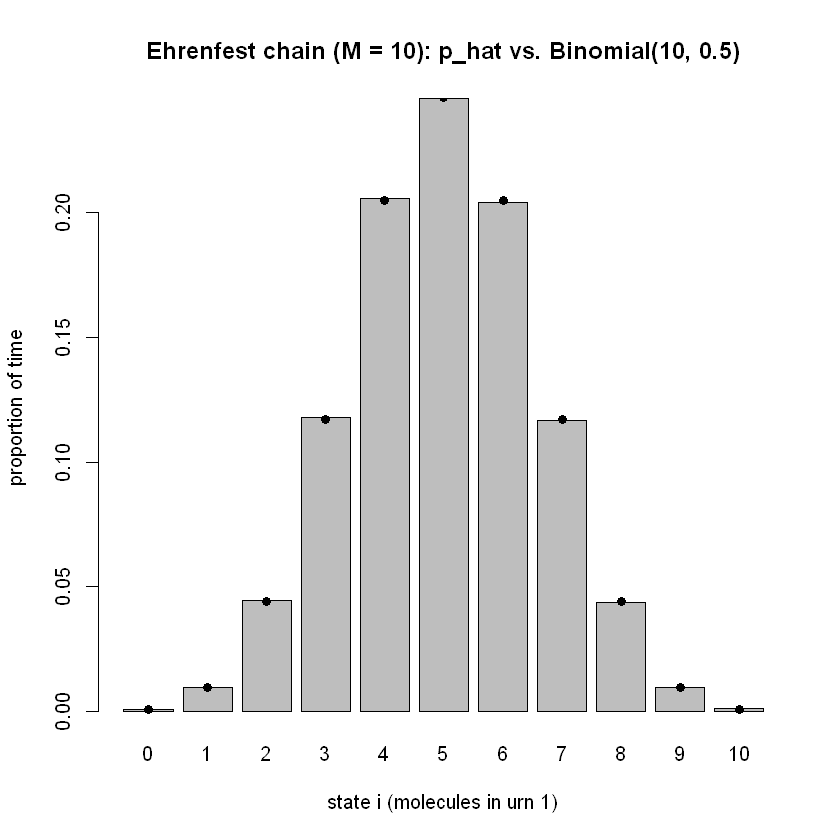

In [16]:
# Stationary distribution (analytic):
# 3) Propose π_i = choose(M, i) * 2^{-M}.
# 4) Prove reversibility (detailed balance):
#      π_i * P[i, i+1]  =  π_{i+1} * P[i+1, i]
#    - Use choose(M, i+1) = choose(M, i) * (M - i)/(i + 1).
# 5) Conclude π is stationary: π P = π (you may also check numerically).
#
# Simulation (Monte Carlo validation):
# 6) Simulate a long Markov chain trajectory:
#      - N = 1e6 steps (reduce if runtime is tight).
#      - Start at state 0 (or any fixed state).
#      - Update: from i, move to i+1 with prob (M - i)/M, else to i-1.
set.seed(631)
N <- 1e6
u <- runif(N)
x <- integer(N)
x[1] <- 0L
for (t in 1:(N - 1)) {
  x[t + 1] <- if (u[t] < (M - x[t]) / M) x[t] + 1L else x[t] - 1L
}

# 7) (Optional) Burn-in: drop the first B = 1e4 states before summarizing.
# 8) Estimate the empirical stationary distribution:
#      - p_hat[i] = proportion of time spent in state i.
p_hat <- tabulate(x + 1, nbins = M + 1) / N

pi_theory <- choose(M, states) * 2^(-M)

# 9) Compute diagnostics:
#      - max_abs_dev = max_i |p_hat[i] − π_i|.
#      - MC SE for each p_hat[i]: sqrt(p_hat[i]*(1 − p_hat[i]) / N_eff),
#        where N_eff ≈ number of post–burn-in samples.
#      - 95% Wald CI: p_hat[i] ± 1.96 * SE[i] (or use Wilson if preferred).
SE <- sqrt(p_hat * (1 - p_hat) / N)
CI_low <- p_hat - 1.96 * SE
CI_high <- p_hat + 1.96 * SE
max_abs_dev <- max(abs(p_hat - pi_theory))
max_abs_dev

#
# Visualization / reporting:
# 10) Produce a tidy table with columns:
#       state, pi_theory, p_hat, SE, CI_low, CI_high, abs_err.
results <- data.frame(state=states, pi_theory=pi_theory, p_hat=p_hat,
    SE=SE, CI_low=CI_low, CI_high=CI_high, abs_err=abs(p_hat - pi_theory))
print(results, digits = 5)

# 11) Make a barplot of p_hat over states with points/lines for π_i
#     (overlay Binomial(M, 0.5) pmf).
bp <- barplot(p_hat, names.arg=states, xlab="state i (molecules in urn 1)",
    ylab="proportion of time", main="Ehrenfest chain (M = 10): p_hat vs. Binomial(10, 0.5)")
points(bp, dbinom(states, M, 0.5), pch = 19)

# Interpretation:
# 12) Comment on agreement between p_hat and π:
#      - Is max_abs_dev small? Do most π_i fall within CI for p_hat[i]?
# 13) Briefly discuss mixing intuition:
#      - Boundary states (0, M) are “sticky”; interior states mix faster.
#      - Longer chains reduce Monte Carlo noise; thinning is unnecessary here.
# ============================================================

max_abs_dev is very small ($\leq 0.001$) and almost all theoretcial $π_i$ fall within their CI. The boundary states are not really stick since, for $j=0$, only state 1 can move to 0, and for $j=M$, only state $M-1$ can move to $M$. The SE decreases as N increases..

## Problem 6 — Entropy and Mutual Information (12 pts)

In [17]:
# ============================================================
# ✅ TODO LIST — Problem 6: Entropy, conditional entropy, mutual information
# ============================================================
# Setup:
# 1) Define the experiment: roll two fair dice (D1, D2 ∈ {1,…,6}).
#    Let X = D1 (first die), and Y = parity(D1 + D2) ∈ {0=even, 1=odd}.
#
# Analytic tasks:
# 2) Compute the marginal pmfs:
#    - P_X(x) = 1/6 for x = 1,…,6.
#    - P_Y(0) = P_Y(1) = 1/2 (by symmetry).
# 3) Compute entropies in bits:
#    - H(X) = −∑_x P_X(x) log2 P_X(x) = log2(6).
#    - H(Y) = −∑_y P_Y(y) log2 P_Y(y) = 1.
# 4) Show X and Y are independent:
#    - For any fixed x, parity(x + D2) is even/odd with probability 1/2.
#    - Conclude P_{X,Y}(x,y) = P_X(x) P_Y(y) and I(X;Y) = 0.
# 5) Using independence, compute:
#    - H(X,Y) = H(X) + H(Y).
#    - H(X|Y) = H(X) (since Y gives no info about X).

All 36 outcomes of $(D_1,D_2)$ have equal probability. Let $X=D_1$ and let $Y=0$ if $D_1+D_2$ is even and $Y=1$ if $D_1+D_2$ is odd.

### Marginal pmfs and independence

$p_X(x)=P\{X=x\}=\dfrac{1}{6}, x=1,\dots,6$

$x+D_2$ is even when $D_2$ has the same parity as $x$ (happens for 3 of the 6 values of $D_2$) and odd when parity is not the same (3/6)

$P_Y(y)=\sum_{x=1}^{6}P_X(x)\,P\{Y=y\mid X=x\}=6\cdot\dfrac{1}{6}\cdot\dfrac{1}{2}=\dfrac{1}{2}$ for $y=0,1$

$P_Y(0)=P_Y(1)=\dfrac{1}{2}$.

### Entropies 

$H(X)=-\sum_{x=1}^{6}\dfrac{1}{6}\log_2\dfrac{1}{6}=\log_2 6=1+\log_2 3\approx 2.584963$

$H(Y)=-\left(\dfrac{1}{2}\log_2\dfrac{1}{2}+\dfrac{1}{2}\log_2\dfrac{1}{2}\right)=1$

### Independence

For any fixed $x$, the parity ($x+D_2$) is even or odd with equal probability ($\dfrac{1}{2}$)

$P_{X,Y}(x,y)=P_X(x)\,P\{Y=y\mid X=x\}=\dfrac{1}{6}\cdot\dfrac{1}{2}=\dfrac{1}{12}=P_X(x)\,P_Y(y), x=1,\dots,6,\; y=0,1$

The joint pmf factors into the product of the marginals for every pair $(x,y)$ so $X$ and $Y$ are independent

### Joint and conditional entropy

$P_{X,Y}(x,y)=P_X(x)P_Y(y)$

$H(X,Y)=-\sum_{x}\sum_{y}P_X(x)P_Y(y)\left[\log_2 P_X(x)+\log_2 P_Y(y)\right]$

$=-\sum_{x}P_X(x)\log_2 P_X(x)\sum_{y}P_Y(y)-\sum_{y}P_Y(y)\log_2 P_Y(y)\sum_{x}P_X(x)$

$=H(X)+H(Y)$

because $\sum_y P_Y(y)=\sum_x P_X(x)=1$

$H(X,Y)=\log_2 6+1=\log_2 12=2+\log_2 3\approx 3.584963$

When $Y=y$ the conditional pmf of $X$ is $P_{X\mid Y}(x\mid y)=\dfrac{1}{6}=P_X(x)$

$H(X\mid Y=y)=-\sum_{x=1}^{6}\dfrac{1}{6}\log_2\dfrac{1}{6}=H(X)$ for each $y$

$H(X\mid Y)=\sum_{y}H(X\mid Y=y)\,P_Y(y)$

$=H(X)\sum_y P_Y(y)=H(X)=\log_2 6\approx 2.584963$

        value analytic  empirical    abs_err
H(X)     H(X)    2.585 2.5850e+00 7.2889e-07
H(Y)     H(Y)    1.000 1.0000e+00 4.5706e-07
H(X,Y) H(X,Y)    3.585 3.5850e+00 3.5017e-06
H(X|Y) H(X|Y)    2.585 2.5850e+00 3.0446e-06
I(X;Y) I(X;Y)    0.000 2.3158e-06 2.3158e-06


[1] 0.0003586667

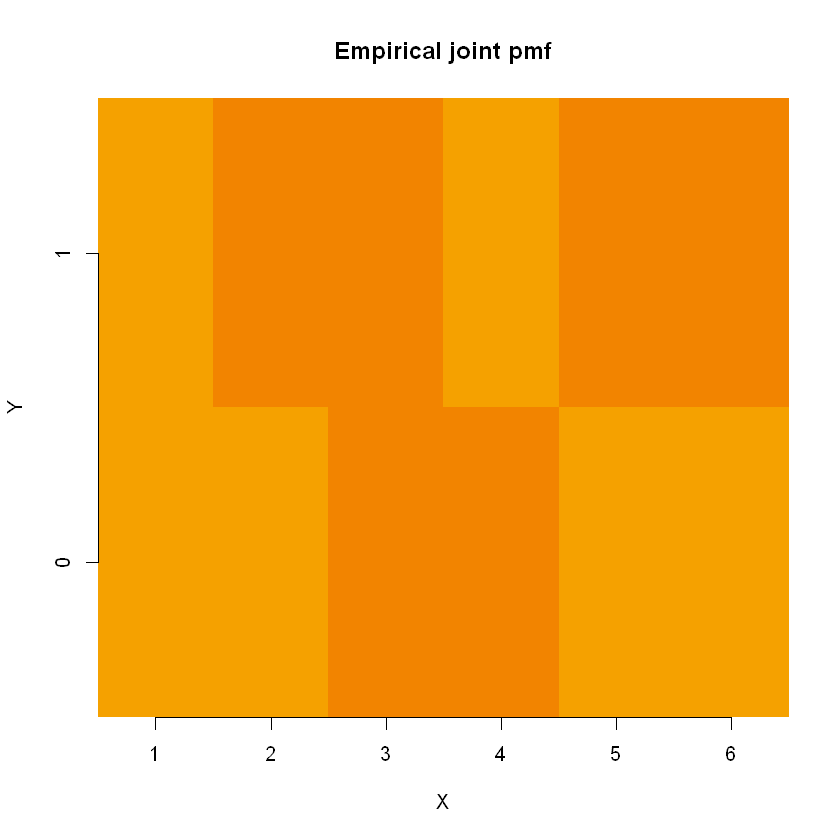

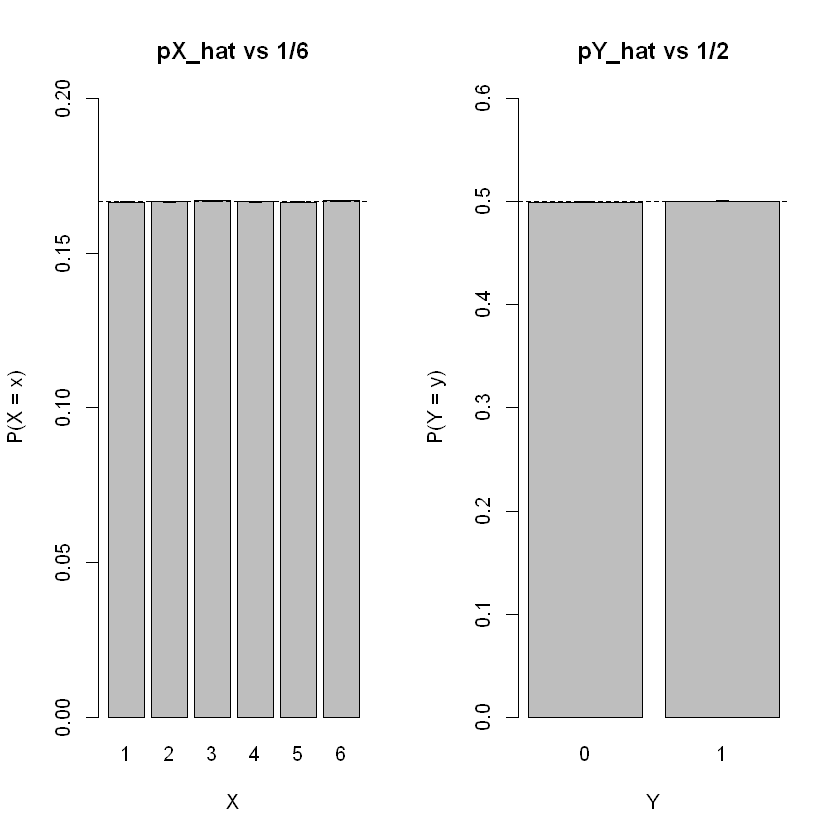

In [18]:
# Simulation tasks (R code):
# 6) Set N = 1e6 simulations (reduce if runtime is tight).
set.seed(631)
N  <- 1e6
D1 <- sample(1:6, N, replace = TRUE)
D2 <- sample(1:6, N, replace = TRUE)

# 7) Generate D1, D2 ~ Uniform{1,…,6}; construct:
X <- D1
Y <- (D1 + D2) %% 2  # 0 even, 1 odd

# 8) Estimate pmfs:
#    - pX_hat (length 6), pY_hat (length 2), and joint pXY_hat (6×2 table / N).
pX_hat  <- as.numeric(table(factor(X, levels = 1:6))) / N
pY_hat  <- as.numeric(table(factor(Y, levels = 0:1))) / N
pXY_hat <- as.matrix(table(factor(X, levels = 1:6), factor(Y, levels = 0:1))) / N

# 9) Compute empirical entropies and mutual information (bits):
#    - H_X_emp, H_Y_emp, H_XY_emp = entropy_bits(pXY_hat)
#      (or H_X_emp = entropy_bits(pX_hat); H_Y_emp = entropy_bits(pY_hat);
#       H_XY_emp = entropy_bits(as.vector(pXY_hat)) )
#    - I_emp = H_X_emp + H_Y_emp − H_XY_emp.
entropy_bits <- function(p) {
    p <- p[p > 0]
    return(-sum(p * log2(p)))
}

H_X_emp  <- entropy_bits(pX_hat)
H_Y_emp  <- entropy_bits(pY_hat)
H_XY_emp <- entropy_bits(as.vector(pXY_hat))
I_emp <- H_X_emp + H_Y_emp - H_XY_emp

H_X_given_Y_emp <- sum(sapply(1:2, function(j)
  pY_hat[j] * entropy_bits(pXY_hat[, j] / pY_hat[j])))

# 10) Create a tidy summary table with analytic vs empirical values:
#     - rows: H(X), H(Y), H(X,Y), H(X|Y), I(X;Y)
#     - columns: analytic, empirical, abs_err.
rows <- c("H(X)", "H(Y)", "H(X,Y)", "H(X|Y)", "I(X;Y)")
analytic <- c("H(X)" = log2(6), "H(Y)" = 1, "H(X,Y)" = log2(12), "H(X|Y)" = log2(6), "I(X;Y)" = 0)
empirical <- c(H_X_emp, H_Y_emp, H_XY_emp, H_X_given_Y_emp, I_emp)
summary_tbl <- data.frame(value=rows, analytic=as.numeric(analytic),
    empirical=empirical, abs_err=abs(empirical - analytic))
print(summary_tbl, digits = 5)
                              
# Optional visualizations:
# 11) Heatmap of the empirical joint pmf pXY_hat (6×2) to illustrate independence
#     (columns nearly equal across rows).
image(x = 1:6, y = 0:1, z = pXY_hat, zlim = c(0, 2/12),
    xlab = "X", ylab = "Y", main = "Empirical joint pmf", axes = FALSE)
axis(1, at = 1:6); axis(2, at = 0:1)
max(abs(pXY_hat - 1/12))

# 12) Barplots comparing pX_hat to 1/6 and pY_hat to 1/2 with error bars (±1.96·SE).
par(mfrow = c(1, 2))
se_X <- mc_se_mean(pX_hat)
bp <- barplot(pX_hat, names.arg = 1:6, ylim = c(0, 0.2),
    xlab = "X", ylab = "P(X = x)", main = "pX_hat vs 1/6")
arrows(bp, pX_hat - 1.96 * se_X, bp, pX_hat + 1.96 * se_X, angle = 90, code = 3, length = 0.05)
abline(h = 1/6, lty = 2)

se_Y <- mc_se_mean(pY_hat)
bp <- barplot(pY_hat, names.arg = 0:1, ylim = c(0, 0.6),
    xlab = "Y", ylab = "P(Y = y)", main = "pY_hat vs 1/2")
arrows(bp, pY_hat - 1.96 * se_Y, bp, pY_hat + 1.96 * se_Y, angle = 90, code = 3, length = 0.05)
abline(h = 1/2, lty = 2)
par(mfrow = c(1, 1))

# Interpretation:
# 13) Briefly discuss:
#     - Are empirical entropies close to analytic values (within Monte Carlo error)?
#     - Is I_emp ≈ 0? Explain why independence holds in this construction.
#     - Any small deviations due to finite-sample noise.
# ============================================================

All empirical values are close to the analytical values and within 1 SE. Empirical $I_{emp}$ is nonzero but very small and positive. $I_{emp} \geq 0$ because $H_Y(X) ≤ H(X)$ for any pmf. Independence holds because the first die does not affect the overall parity. There is no clear indication of error due to sampling noise.

## Problem 7 — Prefix-Free Coding (12 pts)

In [19]:
# ============================================================
# ✅ TODO LIST — Problem 7: Prefix-free coding & noiseless coding theorem
# ============================================================
# Analytic tasks:
# 1) For p = (1/2, 1/4, 1/8, 1/8):
#    - Compute entropy H(X) = −∑ p_i log2 p_i and report in bits.
#    - Verify the proposed prefix-free code {0, 10, 110, 111}:
#         * Check Kraft sum: 2^{-1} + 2^{-2} + 2^{-3} + 2^{-3} = 1.
#         * Verify prefix-free property (no codeword is a prefix of another).
#    - Compute average code length L = ∑ p_i * ℓ_i and compare to H(X).
#


For $p=\left(\dfrac{1}{2},\dfrac{1}{4},\dfrac{1}{8},\dfrac{1}{8}\right)$, $H(X)=-\sum_{i=1}^{4}p(x_i)\log p(x_i)=-\left[\dfrac{1}{2}\log\dfrac{1}{2}+\dfrac{1}{4}\log\dfrac{1}{4}+\dfrac{1}{8}\log\dfrac{1}{8}+\dfrac{1}{8}\log\dfrac{1}{8}\right]=\dfrac{1}{2}+\dfrac{2}{4}+\dfrac{3}{8}+\dfrac{3}{8}=1.75\text{ bits}$

$x_1\to 0,\; x_2\to 10,\; x_3\to 110,\; x_4\to 111,\; n_1=1,\; n_2=2,\; n_3=3,\; n_4=3$

For Kraft's inequality, a code in which no codeword is an extension of another, with lengths $n_1,\dots,n_N$, exists iff $\sum_{i=1}^{N}\left(\dfrac{1}{2}\right)^{n_i}\le 1$

$\sum_{i=1}^{4}\left(\dfrac{1}{2}\right)^{n_i}=\dfrac{1}{2}+\dfrac{1}{4}+\dfrac{1}{8}+\dfrac{1}{8}=1\le 1$ so Kraft's inequality is satisfied.

$0$ is not a prefix of $10$, $110$, or $111$, $10$ is not a prefix of $110$ or $111$, and $110$ is not a prefix of $111$ nor $111$ a prefix of $110$

$L=\sum_{i=1}^{4}n_ip(x_i)=1\cdot\dfrac{1}{2}+2\cdot\dfrac{1}{4}+3\cdot\dfrac{1}{8}+3\cdot\dfrac{1}{8}=\dfrac{1}{2}+\dfrac{1}{2}+\dfrac{3}{8}+\dfrac{3}{8}=1.75\text{ bits}$

$L=H(X)$

In [20]:
# Implementation tasks (R code):
# 2) Write a function `is_prefix_free(code)` that returns TRUE/FALSE by testing all pairs.
is_prefix_free <- function(code) {
    n <- length(code)
    for (i in seq_len(n)) for (j in seq_len(n)) {
        if (i != j && startsWith(code[j], code[i])) {
            return(FALSE)
        }
    }
    return(TRUE)
}

# 3) Implement Shannon coding:
#      shannon_code <- function(p) {
#        # inputs: numeric prob vector p (sum to 1)
#        # outputs: data.frame(symbol, p, length, code)
#        # Steps:
#        #   a) order symbols by decreasing p
#        #   b) cumulative distribution F_k = sum_{i<k} p_i
#        #   c) L_k = ceiling(-log2 p_k)
#        #   d) code_k = first L_k bits of the binary expansion of F_k
#      }
#    - Add small helper(s): normalize probabilities; binary-fraction-to-bits.
normalize_p  <- function(p) {
    return(p / sum(p))
}
entropy_bits <- function(p) {
    p <- p[p > 0]
    return(-sum(p * log2(p)))
}
frac_to_bits <- function(f, L) {
    bits <- character(L)
    for (i in seq_len(L)) {
        f <- f * 2
        if (f >= 1) {
            bits[i] <- "1"
            f <- f - 1
        } else {
            bits[i] <- "0"
        }
    }
    return(paste(bits, collapse = ""))
}
shannon_code <- function(p, symbols = seq_along(p)) {
    keep <- p > 0
    p <- p[keep]
    p <- normalize_p(p)
    ord <- order(-p)
    symbols <- symbols[keep]
    p <- p[ord]; symbols <- symbols[ord]
    F <- c(0, cumsum(p))[seq_along(p)]
    len <- ceiling(-log2(p) - 1e-12)
    code <- unname(mapply(frac_to_bits, F, len))
    out <- data.frame(symbol = symbols, p = p, length = len, code = code, stringsAsFactors = FALSE)
    attr(out, "expected_length") <- sum(p * len)
    return(out)
}
expected_length <- function(tab) {
    sum(tab$p * tab$length)
}

# 4) Validate `shannon_code(p)` on the given p:
#    - Compute table with columns: symbol, p, length, code.
#    - Verify `is_prefix_free(code)` is TRUE.
#    - Compute L_bar = ∑ p_i * length; compare with H(X) and H(X)+1.
p <- c(1/2, 1/4, 1/8, 1/8)
H_p <- entropy_bits(p)
code_given <- c("0", "10", "110", "111")
tab_p <- shannon_code(p)
print(tab_p)
is_prefix_free(tab_p$code)
L_p <- expected_length(tab_p)
c(H = H_p, L_bar = L_p, H_plus_1 = H_p + 1)

#
# 5) Stress test on random distributions:
#    - Generate a random 6-symbol pmf q (e.g., normalize rexp(6)).
#    - Run `shannon_code(q)`; check prefix-free; compute H(q) and L_bar(q).
#    - Confirm H(q) ≤ L_bar(q) ≤ H(q) + 1 (up to small numerical tolerance).
q <- normalize_p(rexp(6))
tab_q <- shannon_code(q)
print(tab_q)
is_prefix_free(tab_q$code)
H_q <- entropy_bits(q)
L_q <- expected_length(tab_q)
c(H = H_q, L_bar = L_q, H_plus_1 = H_q + 1)
stopifnot(L_q >= H_q - 1e-12, L_q < H_q + 1)
sum(2^(-tab_q$length))

#
# Reporting & visualization:
# 6) Produce a tidy summary table for both cases (given p and random q):
#       distribution, H_bits, L_bar, gap = L_bar − H, H_plus_1
# 7) (Optional) Barplot of codeword lengths by symbol probability
#    to illustrate the monotone relationship (higher p ⇒ shorter length).
summary <- data.frame(distribution = c("given p", "random q"), H_bits = c(H_p, H_q),
    L_bar = c(L_p, L_q), gap = c(L_p - H_p, L_q - H_q), H_plus_1 = c(H_p + 1, H_q + 1))
print(summary, digits = 6)

# Interpretation:
# 8) Explain how results illustrate the noiseless coding theorem:
#    - Shannon code achieves average length within 1 bit of entropy.
#    - Discuss why exact equality L = H occurs for the given p.
# ============================================================

  symbol     p length code
1      1 0.500      1    0
2      2 0.250      2   10
3      3 0.125      3  110
4      4 0.125      3  111


[1] TRUE

H    L_bar H_plus_1 
    1.75     1.75     2.75

  symbol          p length  code
1      2 0.36235775      2    00
2      6 0.17543811      3   010
3      3 0.17500302      3   100
4      4 0.17444391      3   101
5      1 0.07980197      4  1110
6      5 0.03295524      5 11110


[1] TRUE

H    L_bar H_plus_1 
2.304026 2.783355 3.304026

[1] 0.71875

  distribution  H_bits   L_bar      gap H_plus_1
1      given p 1.75000 1.75000 0.000000  2.75000
2     random q 2.30403 2.78335 0.479329  3.30403


By noiseless coding theorem average length is at least $H(X)$ and the Shannon code is always $H(X) \leq L \le H(X) + 1$

$L=H$ for the given p because the probabilities are powers of $1/2$ so $−\log_2 p$ is an integer and the ceiling doesn't matter. The Kraft sum is exactly 1 so all codewords are used.

## Problem 8 — Binary Symmetric Channel (12 pts)

In [21]:
# ============================================================
# ✅ TODO LIST — Problem 8: Binary Symmetric Channel (BSC) & Capacity
# ============================================================
# Analytic tasks:
# 1) Define BSC with flip probability q (so p = 1 − q is correctness).
# 2) Majority decoding with repetition length m:
#    - Write the theoretical bit error probability:
#        P_err(m, q) = sum_{j = ceil((m+1)/2)}^m choose(m, j) q^j (1−q)^{m−j}.
#    - Evaluate this for m ∈ {3, 5, 17} at q = 0.2.
# 3) Channel capacity for BSC(q):
#    - C(q) = 1 − h2(q) = 1 + p*log2(p) + (1−p)*log2(1−p), where p = 1−q.
#    - Note: For uniform input X ~ Bern(1/2), I(X;Y) ≤ C(q) with equality at the
#      optimal input (which is indeed 1/2 for BSC).
#



Transmitted bits are received with probability $p$ independently. Let $q=1-p=1-0.2=0.8$ be the probability that a bit is flipped

Transmit each bit an odd $m$ times and decode. The bit is decoded correctly if at most $\frac{m-1}{2}$ of the $m$ copies are flipped. Let $J$ be the number of flipped copies. Flips are independent so $J$ is binomial with parameters $(m,q)$ and an error occurs when $J\ge\frac{m+1}{2}$

$P_{\mathrm{err}}(m,q)=\sum_{j=(m+1)/2}^{m}\binom{m}{j}q^{j}(1-q)^{m-j}$

For $m=3$ (at most 1 error):

$P_{\mathrm{err}}(3,0.2)=(0.2)^3+3(0.2)^2(0.8)=0.008+0.096=0.104$

For $m=5$:

$P_{\mathrm{err}}(5,0.2)=\binom{5}{3}(0.2)^3(0.8)^2+\binom{5}{4}(0.2)^4(0.8)+(0.2)^5=0.0512+0.0064+0.00032=0.05792$

For $m=17$:

$P_{\mathrm{err}}(17,0.2)=\displaystyle\sum_{j=9}^{17}\binom{17}{j}(0.2)^{j}(0.8)^{17-j}\approx 0.00258$

$P_{\mathrm{err}}(17,0.2)\le 0.01$


Noisy coding theorem states that for any rate $R<C^{*}$ and any $\varepsilon>0$ there is a coding-decoding scheme that transmits at $R$ bits/signal with error/bit probability less than $\varepsilon$, and for the binary symmetric channel $C^{*}=1+p\log_2 p+(1-p)\log_2(1-p)$

With $p=0.8$:

$C^{*}=1+0.8\log_2 0.8+0.2\log_2 0.2\approx 1-0.7219=0.2781$ bits/use

In terms of $q$, $C(q)=1-h_2(q)$ where $h_2(q)=-q\log_2 q-(1-q)\log_2(1-q)$.

Repetition with $m=17$ sends only $0.059$ bits/signal so repetition coding is not very efficient

   m     rate err_emp err_theory    abs_err         SE
1  3 0.333333 0.10368  0.1040000 3.2000e-04 0.00068165
2  5 0.200000 0.05873  0.0579200 8.1000e-04 0.00052574
3 17 0.058824 0.00255  0.0025815 3.1463e-05 0.00011277


I_emp   Capacity    abs_gap 
0.27657764 0.27807191 0.00149426

      q      I_emp  Capacity         gap
1  0.00 1.0000e+00 1.0000000 -9.3487e-08
2  0.05 7.1676e-01 0.7136030  3.1559e-03
3  0.10 5.3377e-01 0.5310044  2.7640e-03
4  0.15 3.8923e-01 0.3901597 -9.2487e-04
5  0.20 2.7596e-01 0.2780719 -2.1148e-03
6  0.25 1.8886e-01 0.1887219  1.4090e-04
7  0.30 1.1787e-01 0.1187091 -8.4174e-04
8  0.35 6.6286e-02 0.0659319  3.5387e-04
9  0.40 2.9199e-02 0.0290494  1.4943e-04
10 0.45 7.2966e-03 0.0072255  7.1097e-05
11 0.50 6.1505e-06 0.0000000  6.1505e-06
   m     rate err_emp err_theory    abs_err         SE
1  3 0.333333 0.10368  0.1040000 3.2000e-04 0.00068165
2  5 0.200000 0.05873  0.0579200 8.1000e-04 0.00052574
3 17 0.058824 0.00255  0.0025815 3.1463e-05 0.00011277


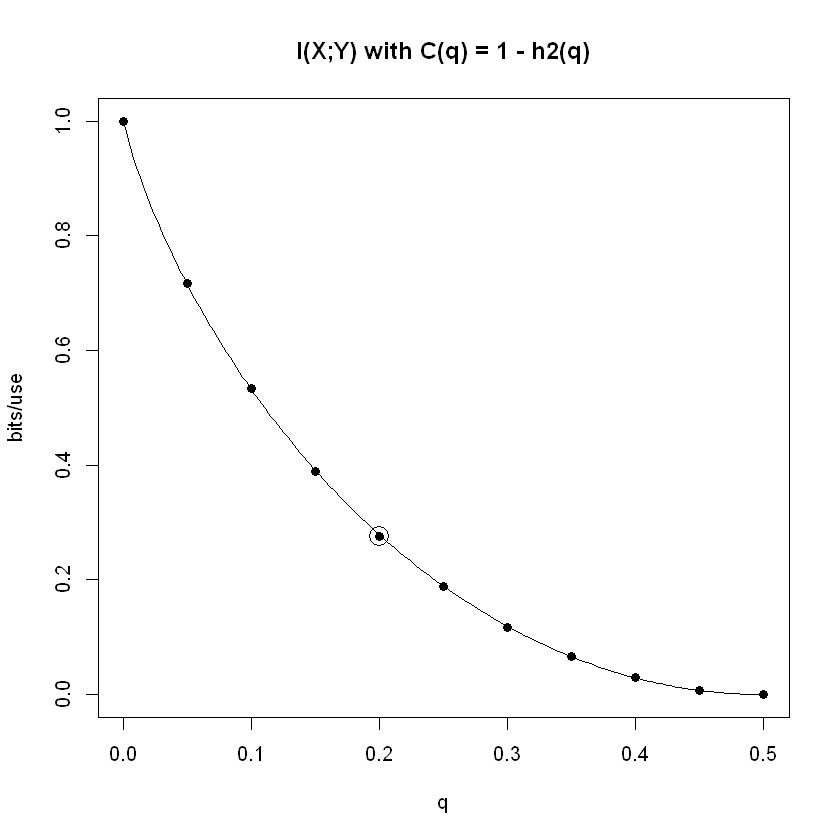

In [22]:
# Simulation tasks (R code):
# 4) Set seed and Monte Carlo size R (e.g., R = 2e5).
set.seed(631)
R <- 2e5
q <- 0.2

# 5) Repetition coding experiment for m ∈ {3,5,17} at q = 0.2:
#    - Generate X ~ Bern(1/2), length R.
#    - Repeat each bit m times; flip each repeated bit independently with prob q.
#    - Majority-decode to get X_hat; estimate empirical error rate:
#        err_emp = mean(X_hat != X).
#    - Compare err_emp to P_err(m, q) (theory) in a tidy table.
P_err <- function(m, q) {
    j <- ((m + 1) / 2):m
    return(sum(choose(m, j) * q^j * (1 - q)^(m - j)))
}
m_vec <- c(3, 5, 17)
rep_tbl <- do.call(rbind, lapply(m_vec, function(m) {
        X <- rbinom(R, 1, 0.5)
        Xrep <- matrix(rep(X, times = m), nrow = R)
        Noise <- matrix(rbinom(R * m, 1, q), nrow = R)
        Yrep <- (Xrep + Noise) %% 2
        X_hat <- as.integer(rowSums(Yrep) > m / 2)
        err_emp <- mean(X_hat != X)
        err_th <- P_err(m, q)
        se <- sqrt(err_emp * (1 - err_emp) / R)
        data.frame(m = m, rate = 1/m, err_emp = err_emp, err_theory = err_th, abs_err = abs(err_emp - err_th), SE = se)
    }
))
print(rep_tbl, digits = 5)


#
# 6) Mutual information estimation at fixed q = 0.2:
#    - Generate X ~ Bern(1/2), pass through single-use BSC(q): Y = X ⊕ Noise, Noise ~ Bern(q).
#    - Form 2×2 joint frequency table for (X, Y); convert to joint pmf p(x,y).
#    - Compute empirical I(X;Y):
#        I_emp = sum_{x,y} p(x,y) log2[ p(x,y) / (p_X(x) p_Y(y)) ].
#    - Compare I_emp to capacity C(q) in bits/use.
mi_bits <- function(x, y){
    pxy <- as.matrix(table(factor(x, levels = 0:1), factor(y, levels = 0:1))) / length(x)
    px <- rowSums(pxy)
    py <- colSums(pxy)
    den <- outer(px, py)
    ok <- pxy > 0
    return(sum(pxy[ok] * log2(pxy[ok] / den[ok])))
}
xlog2x <- function(x) {
    return(ifelse(x > 0, x * log2(x), 0))
}
h2 <- function(q) {
    return(-xlog2x(q) - xlog2x(1 - q))
}
cap <- function(q) {
    return(1 - h2(q))
}

X <- rbinom(R, 1, 0.5)
Z <- rbinom(R, 1, q)
Y <- (X + Z) %% 2
I_emp <- mi_bits(X, Y)
C_q   <- cap(q)
c(I_emp = I_emp, Capacity = C_q, abs_gap = abs(I_emp - C_q))

#
# 7) Capacity curve vs empirical MI across q:
#    - Create a grid q ∈ {0, 0.05, 0.10, ..., 0.50}.
#    - For each q in the grid:
#        * Simulate R pairs (X, Y) as above with uniform input.
#        * Estimate I_emp(q).
#        * Compute C(q) = 1 − h2(q).
#    - Produce a tidy data frame with columns: q, I_emp, Capacity.
q_grid <- seq(0, 0.5, by = 0.05)
curve_df <- data.frame(q = q_grid, I_emp = NA_real_, Capacity = cap(q_grid))
for (k in seq_along(q_grid)) {
    Xk <- rbinom(R, 1, 0.5)
    Yk <- (Xk + rbinom(R, 1, q_grid[k])) %% 2
    curve_df$I_emp[k] <- mi_bits(Xk, Yk)
}
curve_df$gap <- curve_df$I_emp - curve_df$Capacity
print(curve_df, digits = 5)


#
# Visualization:
# 8) Table for repetition coding: m, err_emp, err_theory, abs_err.
print(rep_tbl, digits = 5)

# 9) Plot I_emp(q) vs q with the capacity curve overlaid (lines/points).
#    - Label axes and annotate q = 0.2 point.
qq <- seq(0, 0.5, length.out = 200)
plot(qq, cap(qq), type = "l",
     xlab = "q", ylab = "bits/use",
     main = "I(X;Y) with C(q) = 1 - h2(q)")
points(curve_df$q, curve_df$I_emp, pch = 19)
points(q, I_emp, pch = 1, cex = 2.2)

In [23]:

#
# Interpretation:
# 10) Discuss reliability/latency trade-off of repetition codes:
#     - Larger m ⇒ lower error but higher redundancy.
# 11) Comment on MI vs capacity:
#     - Does I_emp track C(q)? (Finite-sample noise explains small gaps.)
#     - Explain why C(q) decreases to 0 as q → 0.5 and equals 1 at q = 0.
# ============================================================

The theory agrees with the simulated values and all 3 are within the CIs. Increasing $m$ decreases error but the rate decreases with $1/m$ so each bit takes $m$ channel uses which increases redundancy. $I_{emp}$ tracks very closely to $C(q)$ because for a uniform input $I(X;Y)=C)q)$ and sample noise intriduces marginal error. $C(q)$ decreases to 0 as $q \to 0.5$ and equals 1 at $q=0$ because, at $q=0$, every bit is correct so observing $Y$ reveals $X$, and at $q=0.5$, the bit correctness is independent of what was actually sent so observing $Y$ gives no information of $X$.

---
## Implementation & Style Checklist
- Fixed seed; restart & run all is clean.
- Provide interpretation after each result.
- Include 95% CIs where appropriate.